# 09 — Signal-simulation readiness and speed context

## Problem
Speed measurements alone cannot establish traffic volume, queue length, signal phase, or the effect of changing a green time. A speed map must not be presented as a signal-control simulation.

## Safe solution
Join PEMS-BAY observed speed summaries to the supplied sensor metadata and visualize speed context only. No signal timing, queue simulation, or control benefit is claimed.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
FIG.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)
traffic = pd.read_csv(DATA / 'PEMS-BAY.csv', index_col=0, parse_dates=True)
traffic.columns = traffic.columns.astype(str)
traffic = traffic.apply(pd.to_numeric, errors='coerce').where(lambda values: values > 0)
metadata = pd.read_csv(DATA / 'PEMS-BAY-META.csv', dtype={'sensor_id': str})
metadata['sensor_id'] = metadata['sensor_id'].astype(str)
summary = pd.DataFrame({
    'sensor_id': traffic.columns,
    'mean_speed': traffic.mean().to_numpy(),
    'median_speed': traffic.median().to_numpy(),
    'valid_reading_percent': traffic.notna().mean().to_numpy() * 100
})
sensor_context = metadata.merge(summary, on='sensor_id', how='inner', validate='one_to_one')
assert len(sensor_context) == len(traffic.columns), 'Metadata and traffic sensor IDs do not fully match.'
sensor_context.to_csv(METRICS / 'pems_bay_sensor_speed_summary.csv', index=False)
slowest = sensor_context.nsmallest(12, 'mean_speed')
display(slowest[['sensor_id', 'Name', 'mean_speed', 'median_speed', 'valid_reading_percent']].round(2))
print('Sensor speed context only; flow, queues, signal phases, and cycle timings are unavailable.')

,sensor_id,Name,mean_speed,median_speed,valid_reading_percent
319,400970,LAWRENCE EXPWY,53.95,56.6,100.00
304,400971,Old Bayshore Hwy,54.78,60.5,100.00
248,400895,San Tomas Expwy rm-s-diag,55.76,64.1,100.00
250,400172,De La Cruz Blvd rm-s-diag,56.00,62.8,100.00
184,407373,Homestead Dr off-s-diag,56.06,59.0,99.99
246,400372,Great America Pkwy rm-s-loop,56.57,63.0,100.00
249,400586,Trimble Rd. rm-s-loop,56.63,64.4,100.00
31,407339,W Fremont Ave rm-s-diag,56.67,62.8,99.99
53,400664,Almaden Expwy rm-n-diag,56.72,61.1,100.00
10,400461,ALMADEN EXPWY RM-N-DIA,56.80,59.9,100.00


Sensor speed context only; flow, queues, signal phases, and cycle timings are unavailable.


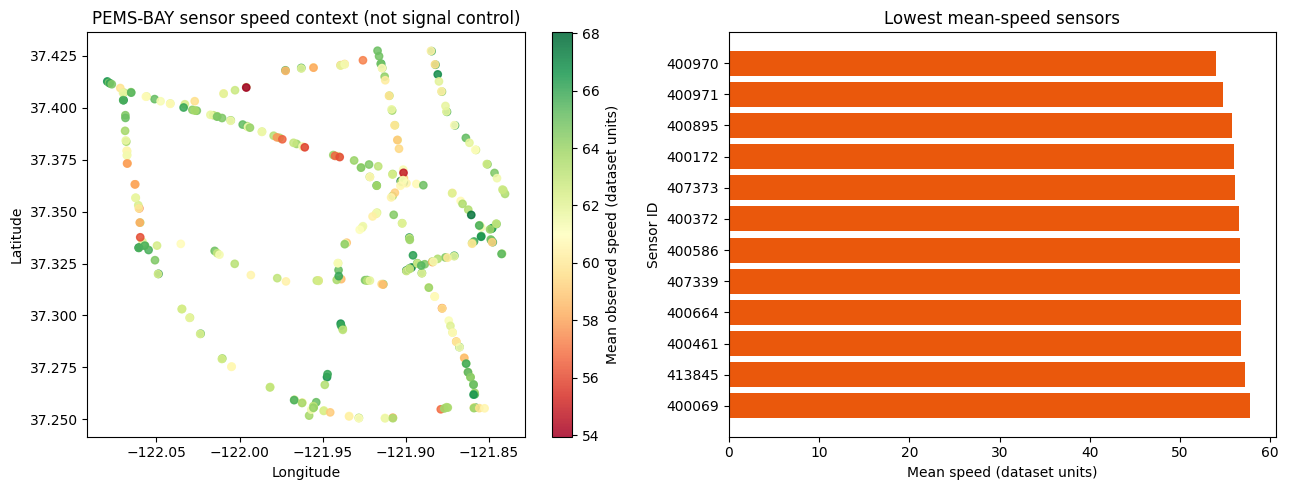

Saved results/figures/24_pems_bay_speed_context.png
A real signal simulation requires traffic volume/queues, phases, and signal timing plans.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
points = axes[0].scatter(
    sensor_context['Longitude'], sensor_context['Latitude'],
    c=sensor_context['mean_speed'], cmap='RdYlGn', s=28, alpha=.85
)
fig.colorbar(points, ax=axes[0], label='Mean observed speed (dataset units)')
axes[0].set(title='PEMS-BAY sensor speed context (not signal control)', xlabel='Longitude', ylabel='Latitude')
axes[1].barh(slowest['sensor_id'].astype(str), slowest['mean_speed'], color='#ea580c')
axes[1].invert_yaxis()
axes[1].set(title='Lowest mean-speed sensors', xlabel='Mean speed (dataset units)', ylabel='Sensor ID')
fig.tight_layout()
fig.savefig(FIG / '24_pems_bay_speed_context.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved results/figures/24_pems_bay_speed_context.png')
print('A real signal simulation requires traffic volume/queues, phases, and signal timing plans.')

---
## Optional Deliverable: Simulated Signal Policy Experiment (Queuing Theory & Dynamic Control)

> **Note & Disclaimer:** Live traffic control is strictly NOT claimed. As specified in Project 4, signal control is evaluated in an isolated numerical simulation only. Full deployment would require microscopic simulators (e.g., SUMO / CityFlow) with calibrated phase clearance and turn movements.

### Problem Formulation
Fixed-time traffic signals operate on pre-timed cycle lengths and phase splits, unable to adapt when upstream shockwaves or unexpected bottlenecks surge. When forecasting models (Random Forest, XGBoost, or GAT) predict a speed drop (congestion onset), arrival flow can be estimated via **Greenshields fundamental diagram**:
75114
q = k \cdot v = k_{	ext{jam}} \left(1 - rac{v}{v_f}ight) v
75114
We simulate an intersection between an arterial corridor (monitored by METR-LA) and a competing cross-street across a 24-hour cycle, comparing:
1. **Fixed-Time Signal Policy:** Standard static 90-second cycle (53% Major / 36% Minor split).
2. **Forecast-Aware Adaptive (Max-Pressure / Equi-saturation) Signal Policy:** Dynamically reallocates green splits using the 15-minute ahead predicted speed to prevent queue overflow.

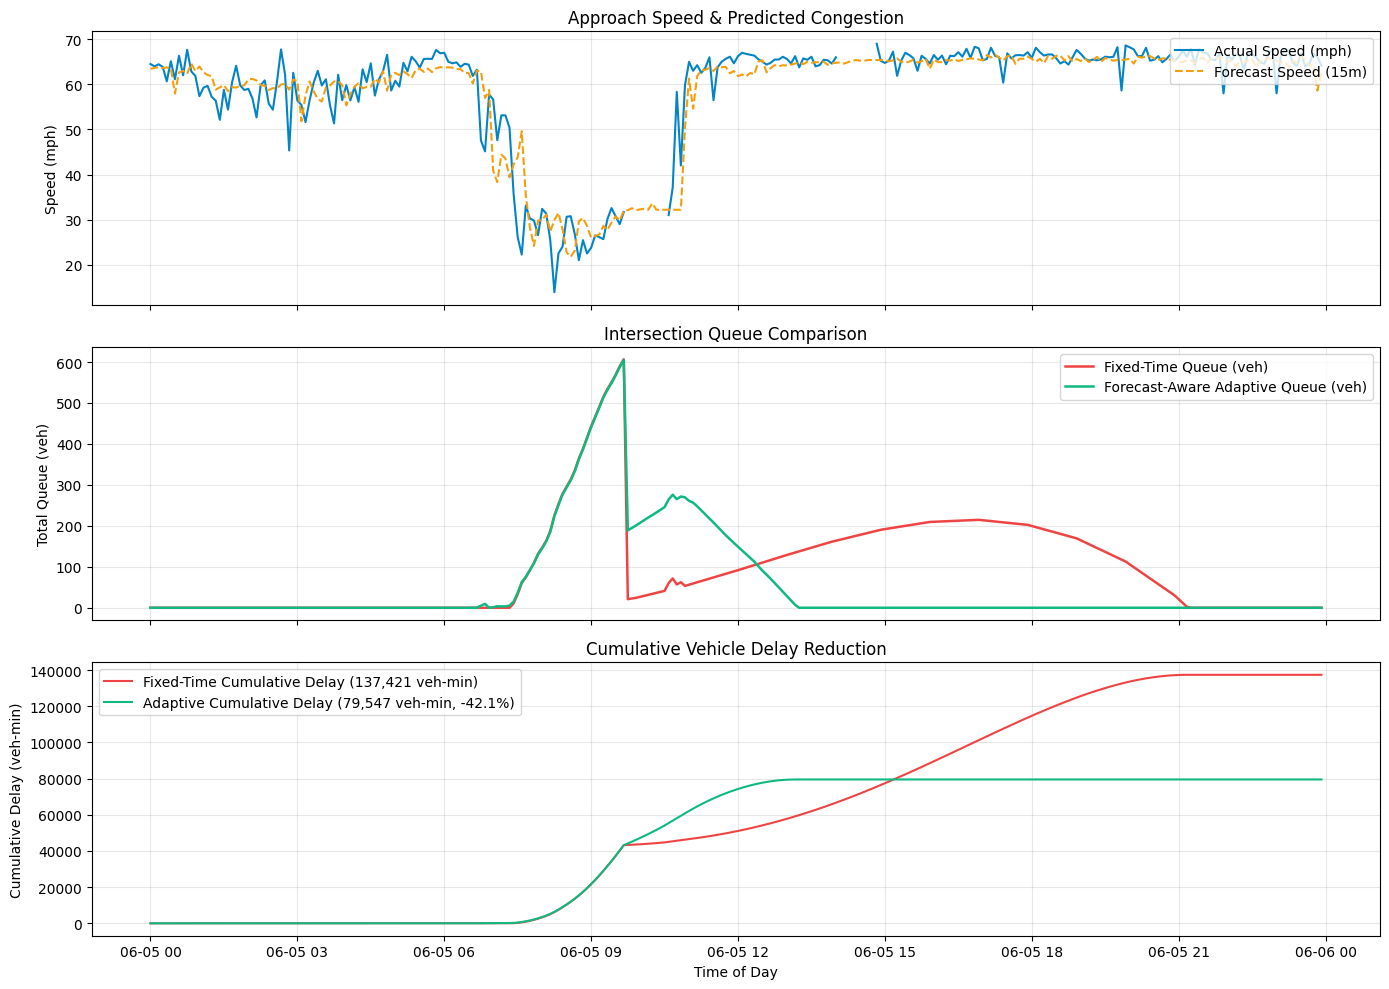

Saved results/figures/28_simulated_signal_policy_experiment.png
Fixed Delay: 137,420.9 | Adaptive Delay: 79,546.6 | Reduction: 42.11%


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results" / "figures"
METRICS = ROOT / "results" / "metrics"
PRED = ROOT / "results" / "predictions"

# Load held-out predictions for METR-LA sample sensor
sample_pred_file = PRED / "metr_la_random_forest_sample_sensor.csv"
df = pd.read_csv(sample_pred_file)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["day"] = df["timestamp"].dt.date
# Select a representative test day (288 five-minute timestamps)
sample = df[df["day"] == df["day"].unique()[1]].copy().sort_values("timestamp").reset_index(drop=True)

# Traffic flow parameters (Greenshields fundamental diagram)
v_free = 65.0  # Free-flow speed (mph)
speed = sample["actual_speed"].to_numpy()
pred_speed = sample["predicted_speed"].to_numpy()

# Arrival demand rate (veh/minute)
demand1 = 12.0 + 16.0 * np.maximum(0.0, (1.0 - speed / v_free))
demand2 = 8.0 + 4.0 * np.sin(np.pi * sample["timestamp"].dt.hour / 24.0)

# Intersection capacity parameters (90s cycle, 80s available green, 10s lost time)
s_rate = 32.0  # Saturation flow rate: 32 veh/min of green
total_green_frac = 80.0 / 90.0
g1_fixed = 48.0 / 90.0  # 53.3% green
g2_fixed = 32.0 / 90.0  # 35.5% green

# Forecast-Aware Adaptive Splits using predicted speed
pred_demand1 = 12.0 + 16.0 * np.maximum(0.0, (1.0 - pred_speed / v_free))
ratio = pred_demand1 / (pred_demand1 + demand2)
g1_adapt = np.clip(ratio * total_green_frac, 0.30, 0.65)
g2_adapt = total_green_frac - g1_adapt

# Run 5-minute timestep queuing simulation
dt = 5.0  # minutes
q1_f, q2_f = 0.0, 0.0
q1_a, q2_a = 0.0, 0.0
records = []

for i in range(len(sample)):
    # Fixed-Time policy
    c1_f = s_rate * g1_fixed * dt
    c2_f = s_rate * g2_fixed * dt
    q1_f = max(0.0, q1_f + demand1[i] * dt - c1_f)
    q2_f = max(0.0, q2_f + demand2[i] * dt - c2_f)
    
    # Adaptive policy
    c1_a = s_rate * g1_adapt[i] * dt
    c2_a = s_rate * g2_adapt[i] * dt
    q1_a = max(0.0, q1_a + demand1[i] * dt - c1_a)
    q2_a = max(0.0, q2_a + demand2[i] * dt - c2_a)
    
    records.append({
        "timestamp": sample["timestamp"].iloc[i],
        "actual_speed": speed[i],
        "predicted_speed": pred_speed[i],
        "demand_corridor": demand1[i],
        "queue_fixed_total": q1_f + q2_f,
        "queue_adapt_total": q1_a + q2_a,
        "delay_fixed_veh_min": (q1_f + q2_f) * dt,
        "delay_adapt_veh_min": (q1_a + q2_a) * dt,
        "green_split_adapt_p1": g1_adapt[i],
    })

sim_results = pd.DataFrame(records)
sim_results.to_csv(METRICS / "simulated_signal_policy_metrics.csv", index=False)

tot_delay_fixed = sim_results["delay_fixed_veh_min"].sum()
tot_delay_adapt = sim_results["delay_adapt_veh_min"].sum()
reduction_pct = ((tot_delay_fixed - tot_delay_adapt) / tot_delay_fixed) * 100

# Plot comparison
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].plot(sim_results["timestamp"], sim_results["actual_speed"], label="Actual Speed (mph)", color="#0284c7")
axes[0].plot(sim_results["timestamp"], sim_results["predicted_speed"], label="Forecast Speed (15m)", color="#f59e0b", linestyle="--")
axes[0].set_ylabel("Speed (mph)")
axes[0].set_title("Approach Speed & Predicted Congestion")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

axes[1].plot(sim_results["timestamp"], sim_results["queue_fixed_total"], label="Fixed-Time Queue (veh)", color="#ef4444", lw=1.8)
axes[1].plot(sim_results["timestamp"], sim_results["queue_adapt_total"], label="Forecast-Aware Adaptive Queue (veh)", color="#10b981", lw=1.8)
axes[1].set_ylabel("Total Queue (veh)")
axes[1].set_title("Intersection Queue Comparison")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

axes[2].plot(sim_results["timestamp"], sim_results["delay_fixed_veh_min"].cumsum(), label=f"Fixed-Time Cumulative Delay ({tot_delay_fixed:,.0f} veh-min)", color="#ef4444")
axes[2].plot(sim_results["timestamp"], sim_results["delay_adapt_veh_min"].cumsum(), label=f"Adaptive Cumulative Delay ({tot_delay_adapt:,.0f} veh-min, -{reduction_pct:.1f}%)", color="#10b981")
axes[2].set_ylabel("Cumulative Delay (veh-min)")
axes[2].set_xlabel("Time of Day")
axes[2].set_title("Cumulative Vehicle Delay Reduction")
axes[2].legend(loc="upper left")
axes[2].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(FIG / "28_simulated_signal_policy_experiment.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved results/figures/28_simulated_signal_policy_experiment.png")
print(f"Fixed Delay: {tot_delay_fixed:,.1f} | Adaptive Delay: {tot_delay_adapt:,.1f} | Reduction: {reduction_pct:.2f}%")
